# Laboratorio 2A · Planificar una operación en PDDL

Son las 7:30 de la mañana en la Planta Norte de **MantenIA**, la empresa de mantenimiento industrial que acompaña este curso. El sistema de mantenimiento acaba de abrir la orden **OT-512**: la bomba 3 tiene una fuga en el sello y debe volver a servicio hoy. Hay dos técnicos disponibles, Ana y Luis, y un sello de repuesto en la bodega. Para una persona con experiencia, el plan parece obvio. Pero las reglas que lo hacen correcto, como bloquear y etiquetar el equipo antes de intervenirlo o que solo intervenga personal certificado, viven en la cabeza de esa persona y no en un sistema que se pueda revisar.

La **planificación automática** convierte ese saber en un modelo explícito: hechos, acciones con precondiciones y efectos, y una meta. Un **planificador** busca la secuencia de acciones que lleva a la meta, y un **validador** comprueba, de forma independiente, que esa secuencia respeta todas las reglas. El lenguaje estándar para escribir estos modelos es **PDDL** (*Planning Domain Definition Language*).

En este laboratorio usted:
* Leerá el modelo PDDL de la orden OT-512 y lo resolverá con **Fast Downward**, un planificador de referencia, a través de la librería **Unified Planning**.
* Validará el plan, lo trazará estado por estado y corregirá un plan escrito a mano con ayuda del validador.
* Formalizará una orden nueva, la OT-518, y comprobará que su modelo produce planes válidos.
* En casa, analizará cómo cambia el plan cuando cambian la meta o los recursos, y modelará una regla de negocio nueva.

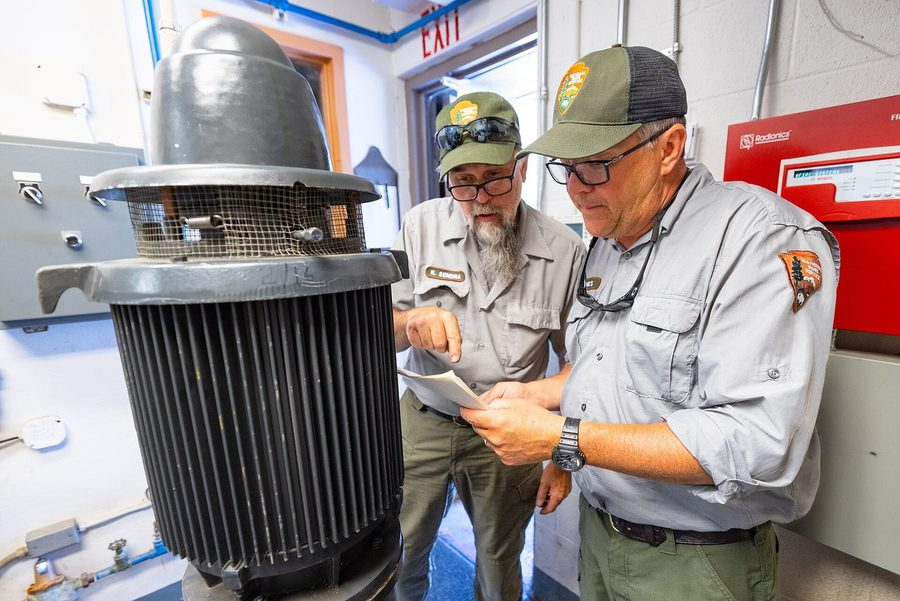

*Un supervisor y un mecánico revisan el esquema de una bomba antes de intervenirla. NPS / Jacob W. Frank, dominio público, [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Gary_Raines,_maintence_supervisor,_and_Rick_Sendra,_maintenance_mechanic,_review_pump_schematics_%2853086631291%29.jpg).*

| | |
| :--- | :--- |
| **Resultado de aprendizaje** | RA4: modelar y resolver problemas de planificación con planificadores y verificar formalmente la validez de las soluciones. |
| **Tiempo** | 35 minutos en clase (secciones 0 a 5) y cerca de una hora en casa (secciones 6 a 9). |
| **Modalidad** | En parejas. |
| **Entrega** | Este notebook ejecutado, al inicio de la semana 2 del curso (detalles en la sección 9). |

## Contenido

* [Antes de empezar](#0)
* [1 - Planificar en MantenIA](#1)
    * [1.1 - Estado, acciones, meta y plan](#1-1)
    * [1.2 - Por qué automatizarlo](#1-2)
* [2 - Del problema al modelo: STRIPS y PDDL](#2)
    * [2.1 - Hechos, mundo cerrado y acciones](#2-1)
    * [2.2 - El dominio: qué acciones existen](#2-2)
    * [2.3 - El problema: objetos, estado inicial y meta](#2-3)
* [3 - Resolver, validar y trazar](#3)
    * [3.1 - Cómo busca un planificador](#3-1)
    * [3.2 - Resolver la OT-512](#3-2)
    * [3.3 - Validar el plan](#3-3)
    * [3.4 - El plan, estado por estado](#3-4)
* [4 - Leer al validador](#4)
* [5 - Formalizar una orden nueva: la OT-518](#5)
* [6 - Cambiar metas y recursos](#6) · *para casa*
* [7 - Una regla de negocio nueva](#7) · *para casa*
* [8 - Opcional: el mismo procedimiento como red jerárquica de tareas](#8)
* [9 - Inténtelo usted mismo, entrega y criterios](#9)
* [Conclusión](#conclusion)
* [Referencias](#referencias)

<details>
<summary><b>💡 Otra forma de navegar: el panel Esquema de VS Code</b> (clic para desplegar)</summary>

VS Code lista todos los títulos de este notebook en el panel **Esquema** (*Outline*), dentro del Explorador de la barra lateral izquierda. Al hacer clic en un título, el notebook salta a esa sección. Si algún enlace de esta tabla no lo lleva a su sección, use el Esquema.

</details>

<a id='0'></a>
## Antes de empezar

Cada celda de código va precedida por una explicación de qué hace y por qué. Ejecútelas **en orden**, de arriba abajo. Solo se editan las celdas marcadas con ✏️; si una todavía tiene partes con `...`, la comprobación automática se lo recordará.

<details>
<summary><b>Cómo usar este notebook en VS Code</b> (si es su primera vez)</summary>

1. Con **Archivo › Abrir carpeta**, abra la carpeta del curso: la que contiene el entorno `.venv` y las carpetas de los laboratorios.
2. En el Explorador, abra el notebook del laboratorio (el archivo `.ipynb`). El notebook trabaja desde su propia carpeta, donde están sus módulos y sus datos.
3. Haga clic en **Seleccionar kernel** (arriba a la derecha) y elija el entorno `.venv` del curso, el que creó en la fase previa con la guía de instalación.
4. Ejecute cada celda con **Shift + Enter** o con el botón ▷ de su izquierda.
5. Si algo falla, lea el mensaje: los módulos de apoyo explican en español qué revisar. Si persiste, use **Reiniciar** y luego **Ejecutar todo**.

</details>

<details>
<summary><b>Respaldo: trabajar en Google Colab</b> (solo si no puede instalar el entorno)</summary>

1. Pida al docente el archivo `lab_2A_planificar_pddl.zip` y abra el notebook en [Colab](https://colab.research.google.com/) con **Archivo › Subir notebook**.
2. En el panel **Archivos** de Colab (ícono de carpeta, a la izquierda), suba `lab_2A_planificar_pddl.zip` a la carpeta `/content`.
3. Ejecute la siguiente celda: detecta Colab, descomprime la carpeta y continúa normalmente.

</details>

* Ejecute la siguiente celda para preparar el entorno. Comprueba la versión de Python e instala las librerías que falten de `requirements.txt` (Unified Planning y el planificador Fast Downward). La primera vez puede tardar uno o dos minutos.

In [ ]:
# Preparar el entorno: comprobar Python e instalar lo que falte de requirements.txt
import os, pathlib, sys, zipfile
if "google.colab" in sys.modules and not pathlib.Path("entorno.py").exists():
    # Respaldo en Colab: descomprimir la carpeta del laboratorio que usted subió como .zip
    zipfile.ZipFile("/content/lab_2A_planificar_pddl.zip").extractall("/content")
    os.chdir("/content/lab_2A_planificar_pddl")
import entorno
entorno.preparar()

El laboratorio usa cuatro módulos de apoyo, en la misma carpeta del notebook: así las celdas quedan cortas y usted se concentra en el modelo, no en la programación.

<details>
<summary><b>Qué hace cada módulo</b> (clic para desplegar)</summary>

* `utilidades_pddl` lee los archivos PDDL, resuelve el problema con Fast Downward, valida planes, explica en español por qué un plan falla y traza un plan estado por estado.
* `presentacion` muestra planes, trazas y veredictos con colores.
* `comprobaciones_2a` revisa sus ejercicios y le da pistas, sin calificar y sin revelar la solución.
* `htn_2a` es un pequeño planificador jerárquico para la sección 8, que es opcional.

Si quiere ver cómo está hecha una función, use `p.mostrar_fuente(...)`; por ejemplo, `p.mostrar_fuente(u.validar)`.

</details>

* Ejecute la siguiente celda para importar los módulos.

In [ ]:
# Importar los módulos de apoyo del laboratorio
import utilidades_pddl as u
import presentacion as p
import comprobaciones_2a as comprobar
import htn_2a as htn

<a id='1'></a>
## 1 - Planificar en MantenIA

Si acaba de ver la exposición del Bloque 1, las secciones 1 y 2 son un repaso: léalas por encima en clase, ejecute sus celdas y vuelva a ellas con calma en casa.

<a id='1-1'></a>
### 1.1 - Estado, acciones, meta y plan

Una jefa de turno con experiencia resuelve la OT-512 así: mira **cómo están las cosas**, piensa en **qué puede hacer** cada técnico, con sus **condiciones** (no se repara un equipo energizado) y sus **consecuencias** (al bloquearlo, queda sin energía), y sabe **qué quiere lograr**. Esas piezas son las de un problema de planificación:

| Pieza | En la OT-512 | Nombre técnico |
| :--- | :--- | :--- |
| Cómo están las cosas al empezar | Ana y Luis en la base; la bomba encendida y averiada; el sello en la bodega; Ana certificada | **Estado inicial** |
| Qué se puede hacer, con qué condiciones y consecuencias | Desplazarse, retirar un repuesto, bloquear, reparar, liberar | **Acciones** con **precondiciones** y **efectos** |
| Qué debe ser cierto al final | La bomba 3 en servicio | **Meta** |
| La respuesta | La secuencia de acciones que lleva del estado inicial a la meta | **Plan** |

Planificar es **buscar** entre los caminos posibles uno que lleve del estado inicial a la meta, y el orden importa: si Ana va primero a la planta, tendrá que devolverse por el sello. Es la búsqueda en espacios de estados de la Sesión 1, con una diferencia que la vuelve general: los estados son **conjuntos de hechos** y las acciones se describen de forma **declarativa**, así que un mismo planificador sirve para mantenimiento, logística o misiones espaciales.

<a id='1-2'></a>
### 1.2 - Por qué automatizarlo

Para una orden pequeña como la OT-512, una persona encuentra el plan en segundos. La planificación automática vale la pena porque **las reglas quedan escritas** como precondiciones que ningún plan válido puede violar, porque **el plan se puede verificar** de forma automática (el tema central de esta unidad: **quien genera el plan no es quien lo certifica**) y porque **escala** a decenas de técnicos, equipos y restricciones que cambian durante el día.

<details>
<summary><b>Para profundizar: tres casos reales</b> (clic para desplegar)</summary>

* **Deep Space 1 (1999).** Entre el 17 y el 21 de mayo de 1999, el software Remote Agent, de NASA Ames y JPL, comandó la sonda Deep Space 1. JPL lo anunció como la primera vez que un software de inteligencia artificial tenía el mando principal de una nave espacial. Recibía objetivos y no secuencias de comandos, y ante una falla simulada replanificó a bordo. El equipo lo vigiló las 24 horas: no fue «sin supervisión humana» (Bernard et al., 2000; Nayak et al., 1999).
* **Rovers de Marte (2004).** El sistema MAPGEN armaba desde la Tierra el plan diario de actividades de Spirit y Opportunity. La planificación era de iniciativa mixta: el planificador proponía y vigilaba las restricciones, y una persona decidía. Los propios desarrolladores reportan que el modo «planificar todo» casi no se usaba, porque sus planes no se podían explicar en la reunión de aprobación (Bresina et al., 2005).
* **Perseverance (2023).** Desde octubre de 2023, el rover usa un planificador a bordo que reajusta su agenda cuando las actividades terminan antes o después de lo previsto (Parjan y Gaines, 2024).

En las organizaciones, la composición de procesos de negocio también se ha modelado como planificación. El caso más ambicioso tradujo a una variante de PDDL el modelo de SAP, con 404 tipos de objetos de negocio y 2 418 transacciones. Quedó como prototipo de investigación (Hoffmann, Weber y Kraft, 2012).

</details>

<a id='2'></a>
## 2 - Del problema al modelo: STRIPS y PDDL

<a id='2-1'></a>
### 2.1 - Hechos, mundo cerrado y acciones

La forma de describir estos problemas viene de **STRIPS**, el planificador que Richard Fikes y Nils Nilsson crearon en 1971 para el robot Shakey, del SRI. Su aporte sigue vigente:

* **Un estado es un conjunto de hechos.** Por ejemplo, `(en ana base)` dice que Ana está en la base y `(encendido bomba3)` que la bomba 3 está encendida.
* **Mundo cerrado.** Todo hecho que no aparece en el estado es falso. Si no está escrito `(certificado luis bomba3)`, Luis no está certificado para la bomba 3.
* **Cada acción tiene tres listas:** sus **precondiciones** (los hechos que deben ser ciertos para aplicarla), los hechos que **agrega** y los que **elimina**. Lo que la acción no menciona no cambia. Así se evita tener que decir, en cada acción, todo lo que permanece igual (el llamado *problema del marco*).

**Desglose de la acción `reparar`**

| | |
| :--- | :--- |
| **Precondiciones** | El técnico está en el lugar del equipo; el equipo está bloqueado y averiado; el técnico lleva un repuesto compatible y está certificado para ese equipo. |
| **Agrega** | El equipo queda reparado. |
| **Elimina** | El equipo deja de estar averiado; el técnico deja de llevar el repuesto, porque se consumió. |
| **Por qué importa** | La norma de seguridad (bloquear antes de intervenir) y la de certificación son precondiciones: el planificador nunca producirá un plan que las viole. |

<details>
<summary><b>Para profundizar: los supuestos de la planificación clásica</b> (clic para desplegar)</summary>

Este modelo, llamado **planificación clásica**, supone que el mundo es **determinista** (cada acción hace exactamente lo que dice), **completamente observable** (se conoce todo el estado) y que las acciones son **instantáneas** y se ejecutan **una a la vez**. En la realidad, un sello puede venir defectuoso o un técnico puede ausentarse. Por eso los sistemas reales **monitorean** la ejecución y **replanifican** cuando lo observado no coincide con lo esperado. Lo practicará en el Laboratorio 2C.

</details>

<a id='2-2'></a>
### 2.2 - El dominio: qué acciones existen

PDDL separa el modelo en dos archivos. El **dominio** describe el tipo de mundo: qué clases de objetos hay, qué hechos pueden ser ciertos y qué acciones existen. Se escribe una vez y sirve para muchas órdenes. Sus partes son:

* `(:requirements :strips :typing)`: las capacidades del lenguaje que se usan; aquí, acciones al estilo STRIPS y objetos con tipo.
* `(:types ...)`: las clases de objetos (`tecnico`, `equipo`, `repuesto`, `lugar`).
* `(:predicates ...)`: los hechos posibles. `(en ?t - tecnico ?l - lugar)` dice que el hecho `en` relaciona un técnico con un lugar; los nombres que empiezan con `?` son **variables**.
* `(:action ...)`: cada acción, con sus `:parameters`, su `:precondition` y su `:effect`. Dentro de un efecto, `(not ...)` significa «elimina este hecho». Varios hechos se agrupan con `(and ...)`: en una precondición, todos deben cumplirse; en un efecto, todos ocurren.

* Ejecute la siguiente celda para ver el dominio completo de MantenIA.

In [ ]:
# Mostrar el dominio de MantenIA con colores
DOMINIO = "pddl/mantenia_dominio.pddl"
p.mostrar_pddl(open(DOMINIO, encoding="utf-8").read(), "Dominio de MantenIA · pddl/mantenia_dominio.pddl")

Lea cada acción como una regla de trabajo:

| Acción | En palabras |
| :--- | :--- |
| `desplazarse` | Un técnico va de un lugar a otro: deja de estar en el origen y pasa a estar en el destino. |
| `retirar-repuesto` | Un técnico que está en el lugar donde se almacena un repuesto lo retira: el repuesto deja de estar almacenado y el técnico lo lleva. |
| `bloquear` | Un técnico certificado, en el lugar de un equipo encendido, lo bloquea y etiqueta: el equipo queda bloqueado y deja de estar encendido. |
| `reparar` | Un técnico certificado, en el lugar de un equipo bloqueado y averiado, con un repuesto compatible, lo repara: el equipo queda reparado y el repuesto se consume. |
| `liberar` | Un técnico, en el lugar de un equipo bloqueado y reparado, retira el bloqueo: el equipo queda en servicio y encendido. |

> **Nota:** fíjese en que `liberar` no exige que el técnico esté certificado. Volveremos sobre esto en la sección 6.

<a id='2-3'></a>
### 2.3 - El problema: objetos, estado inicial y meta

El **problema** describe una situación concreta: qué objetos hay hoy (`:objects`), qué es cierto al empezar (`:init`) y qué se quiere lograr (`:goal`). En `:objects`, cada grupo de nombres termina con su tipo: `ana luis - tecnico` declara dos técnicos. Fíjese en lo que el problema **no** dice: no dice cómo lograrlo. Encontrar el cómo es trabajo del planificador.

> **Nota sobre los nombres:** en PDDL use solo letras sin tilde, números y guiones (`tecnico`, `planta-norte`). Con tildes o ñ, muchos planificadores fallan, a veces sin mostrar ningún error.

* Ejecute la siguiente celda para ver el problema de la OT-512.

In [ ]:
# Mostrar el problema de la orden OT-512
OT512 = "pddl/ot512.pddl"
p.mostrar_pddl(open(OT512, encoding="utf-8").read(), "Problema de la orden OT-512 · pddl/ot512.pddl")

Ahora lea el modelo con Unified Planning. La función `u.leer_problema` revisa que los dos archivos estén bien escritos (si no lo están, explica en español qué corregir) y devuelve el problema listo para resolver. Luego `u.estado_inicial` lista los hechos ciertos al empezar.

* Ejecute la siguiente celda para leer el modelo y ver su estado inicial.

In [ ]:
# Leer el dominio y el problema, y mostrar el estado inicial
ot512 = u.leer_problema(DOMINIO, OT512)
p.mostrar_estado(u.estado_inicial(ot512), "Estado inicial de la OT-512")
print("Meta:", u.metas(ot512))

Son 8 hechos. Por el supuesto de mundo cerrado, todo lo demás es falso. Por ejemplo, no aparece `(certificado luis bomba3)`, así que Luis no está certificado para la bomba 3, y no aparece `(lleva ana sello)`, así que nadie tiene el sello en la mano.

<a id='3'></a>
## 3 - Resolver, validar y trazar

<a id='3-1'></a>
### 3.1 - Cómo busca un planificador

El número de caminos crece muy rápido, así que el planificador **estima qué tan lejos está de la meta** desde cada estado y explora primero los más prometedores, como la heurística de A*. **Fast Downward** (Helmert, 2006), en su configuración por defecto, es un planificador **satisfactorio**: devuelve rápido un plan válido, pero no garantiza que sea el más corto. En la sección 6 lo comparará con uno **óptimo**.

<details>
<summary><b>Para profundizar: de dónde sale la estimación</b> (clic para desplegar)</summary>

La idea más influyente es **relajar el problema**: ignorar los efectos que eliminan hechos. En el mundo relajado nada se pierde (Ana puede «estar» en todas partes a la vez), así que encontrar un plan aproximado es fácil, y contar sus acciones estima la distancia real. El planificador FF popularizó esta heurística (Hoffmann y Nebel, 2001). Unified Planning ejecuta Fast Downward con la configuración **LAMA** en su modo de primer plan (*lama-first*), que combina esa heurística con *landmarks*, hechos que todo plan debe lograr en algún momento (Richter y Westphal, 2010). La configuración óptima usa búsqueda A* con una heurística admisible (LM-cut): garantiza el plan más corto, a cambio de más cómputo.

</details>

<a id='3-2'></a>
### 3.2 - Resolver la OT-512

**Desglose del experimento**

| | |
| :--- | :--- |
| **Entrada** | El dominio de MantenIA y el problema de la OT-512. |
| **Qué debería pasar** | Un plan de 6 pasos en el que Ana va a la bodega por el sello, va a la planta, bloquea, repara y libera la bomba 3. |
| **Por qué se cumple** | El sello está en la bodega, así que hay que retirarlo antes de reparar. Luis no está certificado, así que las precondiciones de `bloquear` y `reparar` lo descartan, sin que nadie se lo diga al planificador. |

* Ejecute la siguiente celda para resolver la OT-512 con Fast Downward.

In [ ]:
# Resolver la OT-512 con Fast Downward (configuración por defecto de Unified Planning)
resultado = u.resolver(ot512)
p.mostrar_planificacion(resultado)

<br>

### Análisis

El planificador encontró el plan de 6 pasos en una fracción de segundo; el tiempo incluye arrancar el programa.

* **Nadie le dijo que eligiera a Ana.** La precondición `(certificado ?t ?e)` de `bloquear` y de `reparar` descarta a Luis. Las reglas del negocio, escritas como precondiciones, deciden por sí solas quién puede hacer qué.
* **El orden sale del modelo.** Ana pasa por la bodega antes de ir a la planta porque `reparar` exige llevar el repuesto, y bloquea antes de reparar porque `reparar` exige `(bloqueado bomba3)`.

<a id='3-3'></a>
### 3.3 - Validar el plan

Un **validador** toma el modelo y un plan, y simula el plan paso a paso: comprueba que cada acción cumpla sus precondiciones en el estado en que se aplica, aplica sus efectos y, al final, comprueba que se cumpla la meta. No busca nada; solo verifica. El validador clásico de la comunidad de planificación es **VAL** (Howey, Long y Fox, 2004); aquí se usa el validador incluido en Unified Planning, que cumple la misma función.

¿Por qué validar un plan que acaba de producir un planificador? Porque **quien genera no es quien certifica**: los planes también los escriben personas o modelos de lenguaje (Laboratorio 2B), y el validador es el mismo para todos.

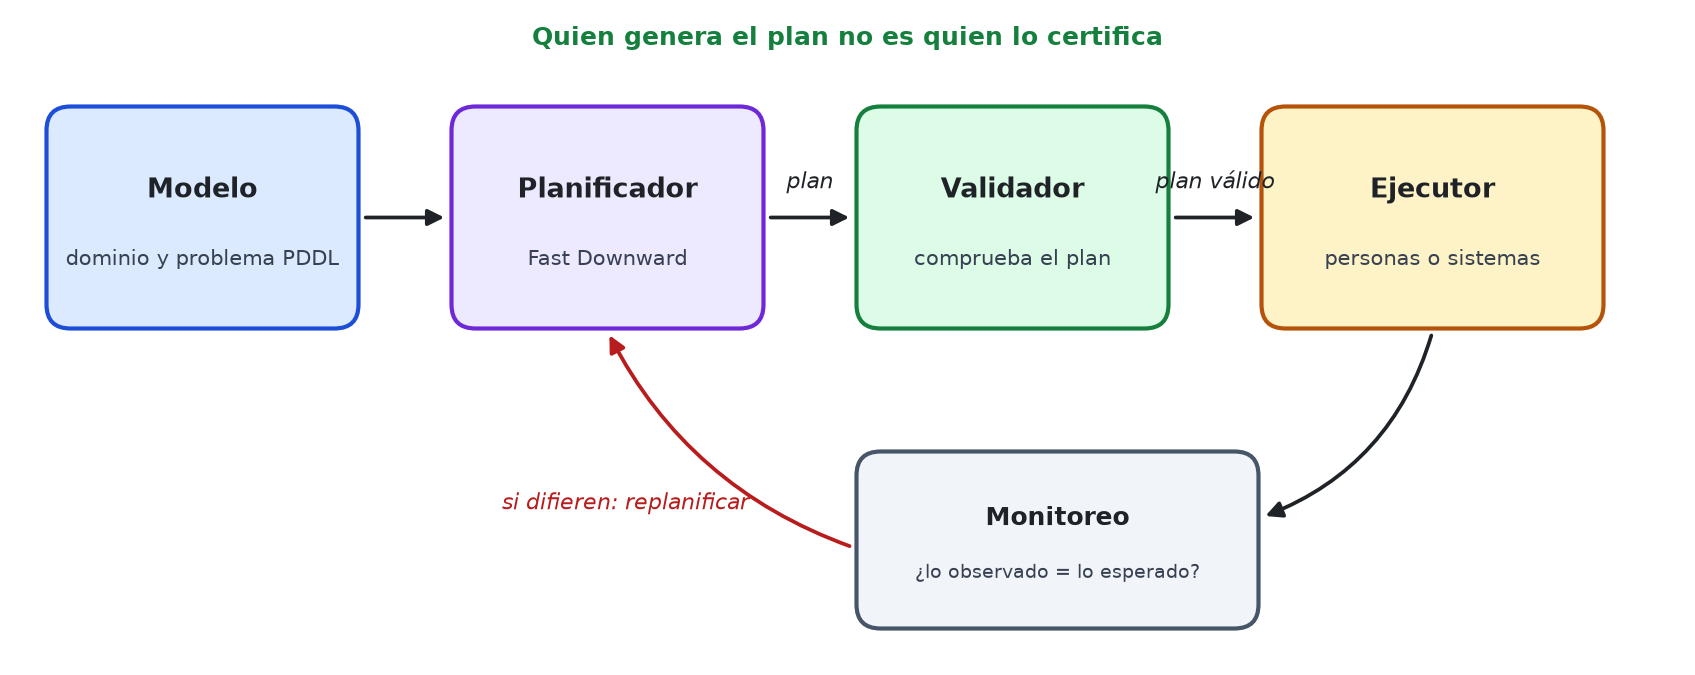

*Un sistema de planificación separa responsabilidades: el modelo describe el mundo, el planificador busca, el validador certifica y el ejecutor actúa. El monitoreo compara lo observado con lo esperado y, si difieren, se replanifica (Laboratorio 2C).*

* Ejecute la siguiente celda para validar el plan.

In [ ]:
# Validar el plan de Fast Downward con el validador de Unified Planning
validacion = u.validar(ot512, resultado.plan)
p.mostrar_veredicto(validacion)

<a id='3-4'></a>
### 3.4 - El plan, estado por estado

La **traza** muestra cómo cambia el estado con cada acción: en verde los hechos que la acción agrega y, tachados en rojo, los que elimina.

* Ejecute la siguiente celda para trazar el plan.

In [ ]:
# Trazar el plan: hechos agregados y eliminados en cada paso
p.mostrar_traza(u.trazar(ot512, resultado.plan))

<br>

### Análisis

Deténgase en tres pasos:

* **Paso 4, `bloquear`.** Elimina `(encendido bomba3)` y agrega `(bloqueado bomba3)`, que es justo la precondición que necesita `reparar`.
* **Paso 5, `reparar`.** El repuesto se consume: desaparece `(lleva ana sello)`. La bomba deja de estar averiada y queda reparada.
* **Paso 6, `liberar`.** Quita el bloqueo, vuelve a encender el equipo y agrega `(en-servicio bomba3)`, la meta.

Los hechos que ninguna acción cambia, como `(certificado ana bomba3)`, son los **fijos** del problema: las precondiciones los consultan.

<a id='4'></a>
## 4 - Leer al validador

Ahora el plan no viene del planificador. Un supervisor lo escribió a mano, de memoria. Parece razonable, pero comete el error más típico: omitir una precondición. En el Laboratorio 2B verá que un modelo de lenguaje puede cometer este mismo error.

**Desglose del experimento**

| | |
| :--- | :--- |
| **Entrada** | Un plan de 5 pasos escrito a mano: Ana va a la bodega, retira el sello, va a la planta, repara la bomba y la libera. |
| **Qué debería pasar** | El validador lo rechaza en el paso 4. |
| **Cómo falla** | `reparar` exige `(bloqueado bomba3)`, y ningún paso anterior bloqueó la bomba. En la realidad, la bomba se repararía energizada. |

La función `u.plan_desde_texto` convierte un plan escrito como texto, con una acción por línea, en un plan que el validador puede revisar. Si una acción o un objeto no existen, o si una línea no tiene el formato de una acción, lo dice.

* Ejecute la siguiente celda para validar el plan escrito a mano y ver su traza.

In [ ]:
# Validar un plan escrito a mano (le falta un paso) y trazarlo hasta donde se puede
plan_a_mano = """
(desplazarse ana base bodega)
(retirar-repuesto ana sello bodega)
(desplazarse ana bodega planta-norte)
(reparar ana bomba3 sello planta-norte)
(liberar ana bomba3 planta-norte)
"""
lectura = u.plan_desde_texto(ot512, plan_a_mano)
p.mostrar_veredicto(u.validar(ot512, lectura.plan))
p.mostrar_traza(u.trazar(ot512, lectura.plan))

El veredicto trae dos mensajes. El primero lo escribe el módulo de apoyo, en español. El segundo es el mensaje original del validador, en inglés: *Preconditions [bloqueado(bomba3)] of 4-th action instance reparar(...) are not satisfied*. Los dos dicen lo mismo: en el paso 4 no se cumple `(bloqueado bomba3)`. La traza se detiene justo ahí.

### ✏️ Ejercicio 1: corregir el plan

Corrija el plan agregando, en el lugar de `...`, la acción que falta. Use el formato `(accion argumento1 argumento2 ...)`.

<details>
<summary><b>Pista</b> (clic para desplegar)</summary>

La acción que agrega `(bloqueado ?e)` es `bloquear`. Sus parámetros son, en este orden, el técnico, el equipo y el lugar.

</details>

* Complete la celda y ejecútela. La comprobación valida su plan y le dice si quedó bien.

In [ ]:
# ✏️ Ejercicio 1: reemplace ... por la acción que falta
plan_corregido = """
(desplazarse ana base bodega)
(retirar-repuesto ana sello bodega)
(desplazarse ana bodega planta-norte)
...
(reparar ana bomba3 sello planta-norte)
(liberar ana bomba3 planta-norte)
"""
comprobar.comprobar_plan_corregido(ot512, plan_corregido)

<a id='5'></a>
## 5 - Formalizar una orden nueva: la OT-518

Hasta aquí usó un modelo ya escrito. Ahora el modelo lo escribe usted. El sistema de mantenimiento abre esta orden:

> **OT-518 · prioridad alta.** Dos equipos están averiados y siguen energizados: la **bomba 3** de la Planta Norte, con fuga en el sello, y el **compresor 2** de la Planta Sur, con un rodamiento dañado. En la bodega hay un **sello** compatible con la bomba 3 y un **rodamiento** compatible con el compresor 2. **Ana** está certificada para la bomba 3; **Luis**, para el compresor 2. Los dos técnicos empiezan en la base. Meta: los dos equipos en servicio.

El dominio no cambia: las acciones son las mismas. Solo hay que escribir el **problema**, y la celda ya trae los objetos y los hechos de ubicación (dónde empieza cada técnico, dónde está cada equipo y cada repuesto). Complete el resto:

1. **Estado inicial.** Agregue un hecho por cada cosa que la orden afirma y que todavía no está escrita: que cada equipo está encendido y averiado, con qué equipo es compatible cada repuesto y quién está certificado para qué.
2. **Meta.** Cuando hay varios hechos, se agrupan con `(and ...)`.

**Desglose del experimento**

| | |
| :--- | :--- |
| **Entrada** | Su problema PDDL de la OT-518. |
| **Qué debería pasar** | El planificador encuentra un plan de 12 pasos: Ana atiende la bomba 3 y Luis el compresor 2. |
| **Cómo puede fallar** | Si su modelo no dice lo mismo que la orden, el planificador resuelve otro problema. Si **falta** un hecho, el modelo suele quedar sin solución: sin `(encendido compresor2)`, nadie puede bloquear el compresor, porque `bloquear` exige que el equipo esté encendido. Si un hecho está **equivocado**, el plan puede fallar en la realidad: si en lugar de `(certificado luis compresor2)` escribe `(certificado ana compresor2)`, el planificador manda a Ana al compresor, y en la orden real Ana no está certificada para él. La comprobación lo detecta: toma el plan de **su** modelo y lo valida contra la orden real. |

### ✏️ Ejercicio 2: escribir el problema de la OT-518

* Complete las partes marcadas con `...` y ejecute la celda. Si algo falla, la comprobación le dice qué tipo de hecho revisar, sin darle la respuesta.

In [ ]:
# ✏️ Ejercicio 2: complete el problema de la OT-518 (reemplace cada ...)
OT518 = """
(define (problem ot-518)
  (:domain mantenia)
  (:objects ana luis - tecnico
            bomba3 compresor2 - equipo
            sello rodamiento - repuesto
            base bodega planta-norte planta-sur - lugar
  )
  (:init (en ana base) (en luis base)
         (ubicado bomba3 planta-norte) (ubicado compresor2 planta-sur)
         (almacenado sello bodega) (almacenado rodamiento bodega)
         ...
  )
  (:goal ...)
)
"""
comprobar.comprobar_ot518(DOMINIO, OT518)

Cuando la comprobación sea exitosa, mire la traza del plan de su modelo.

* Ejecute la siguiente celda para trazar el plan de la OT-518.

In [ ]:
# Trazar el plan de la OT-518 que produce su modelo
if "..." in OT518:
    p.nota("Primero complete el ejercicio 2.", "aviso")
else:
    try:
        ot518 = u.leer_problema(DOMINIO, OT518)
        resultado_518 = u.resolver(ot518)
        p.mostrar_planificacion(resultado_518)
        if resultado_518.plan:
            p.mostrar_traza(u.trazar(ot518, resultado_518.plan))
    except u.ErrorPDDL as error:
        p.nota(str(error), "error", "Revise el ejercicio 2")

<br>

### Análisis

* **El planificador reparte el trabajo.** Nadie le dijo que Luis atiende el compresor y Ana la bomba: lo deducen las precondiciones de certificación, igual que en la OT-512.
* **Un plan secuencial no es un horario.** Fast Downward entrega las 12 acciones en fila, pero las de Ana y las de Luis no dependen entre sí: en la práctica pueden hacerse **en paralelo**. Lo que el plan fija es el orden dentro de cada cadena de dependencias, como retirar el repuesto y bloquear antes de reparar. En el Laboratorio 2C verá un plan escrito en lenguaje natural, el plan.md, que declara esas dependencias de forma explícita (*«requiere 1 y 2»*).
* **Validar contra la orden real.** La comprobación no se conformó con que su modelo tuviera solución: tomó el plan de su modelo y lo validó contra el modelo de referencia. Un modelo puede tener solución y aun así describir mal la realidad.

---

### ⏸ Hasta aquí, el trabajo en clase

Las secciones 6 a 9 se trabajan en casa: unos 60 minutos, más la sección 8 si quiere hacer la parte opcional.

---

<a id='6'></a>
## 6 - Cambiar metas y recursos

En una organización, las condiciones cambian durante el día. Aparece una meta adicional, el repuesto está en otra planta, una certificación vence o se certifica a otra persona. Con el procedimiento en la cabeza de alguien, cada cambio obliga a repensar todo. Con un modelo, basta cambiar una línea y volver a planificar.

La función `u.variante` construye una versión modificada de un problema: agrega o quita hechos del estado inicial, cambia la meta o agrega objetos. Así se responde a preguntas del tipo **«¿qué pasa si...?»**.

**Desglose del experimento**

| Variante | Cambio en el modelo | Qué debería pasar |
| :--- | :--- | :--- |
| **a)** Meta adicional | La meta pide además `(en ana base)`: Ana debe volver a la base al terminar. | Un plan más largo, que termina con Ana en la base. |
| **b)** Repuesto en la Planta Sur | El sello no está en la bodega sino en la Planta Sur. | Un plan con otra ruta. |
| **c)** Sin técnico certificado | Se quita `(certificado ana bomba3)`: venció la certificación de Ana. | Ningún plan: el problema no tiene solución. |
| **d)** Luis también certificado | Se agrega `(certificado luis bomba3)`. | Un plan válido con cualquiera de los dos técnicos. |

<a id='6-1'></a>
### 6.1 - Cuatro variantes de la OT-512

* Ejecute la siguiente celda para construir las cuatro variantes, resolverlas y resumir los resultados en una tabla.

In [ ]:
# Construir las cuatro variantes de la OT-512, resolverlas y resumir los resultados
texto_512 = open(OT512, encoding="utf-8").read()
variantes = {
    "a) meta adicional": u.variante(texto_512, meta=["(en-servicio bomba3)", "(en ana base)"]),
    "b) repuesto en la Planta Sur": u.variante(texto_512, quitar=["(almacenado sello bodega)"],
                                               agregar=["(almacenado sello planta-sur)"], objetos={"lugar": ["planta-sur"]}),
    "c) sin técnico certificado": u.variante(texto_512, quitar=["(certificado ana bomba3)"]),
    "d) Luis también certificado": u.variante(texto_512, agregar=["(certificado luis bomba3)"]),
}
resultados = {}
filas = []
for nombre, texto in variantes.items():
    problema = u.leer_problema(DOMINIO, texto)
    r = u.resolver(problema)
    resultados[nombre] = (problema, r)
    quienes = sorted({paso.split()[1] for paso in r.pasos})
    filas.append({"variante": nombre, "resultado": u.NOMBRE_ESTADO[r.estado], "pasos": len(r.pasos) or "—",
                  "técnicos que actúan": ", ".join(quienes) or "—"})
p.mostrar_tabla(filas, titulo="Variantes de la OT-512 con el planificador satisfactorio (lama-first)")

La variante **c)** no tiene solución, y el planificador lo **demuestra**: no es que se rindiera, sino que comprobó que la meta es inalcanzable. Sin nadie certificado, `bloquear` no se puede aplicar nunca y, sin bloqueo, no hay reparación. Para una organización, saber que una orden es imposible con los recursos actuales es tan útil como tener un plan: hay que escalar, certificar a alguien o pedir apoyo.

En la variante **d)**, el planificador elige a uno de los dos técnicos certificados según el orden en que explora las acciones: el modelo no le da ninguna razón para preferir a uno. Si importara quién va, por carga de trabajo o por costo, habría que modelarlo.

<a id='6-2'></a>
### 6.2 - Mirar los planes de cerca

Ahora compare, para las variantes **a)** y **b)**, el plan del planificador satisfactorio con el del planificador **óptimo** (`fast-downward-opt`, búsqueda A* con la heurística LM-cut), que garantiza el plan más corto.

* Ejecute la siguiente celda para ver los dos planes de cada variante.

In [ ]:
# Comparar, en las variantes a) y b), el plan satisfactorio con el plan óptimo
for nombre in ["a) meta adicional", "b) repuesto en la Planta Sur"]:
    problema, satisfactorio = resultados[nombre]
    optimo = u.resolver(problema, motor="fast-downward-opt")
    p.mostrar_plan(satisfactorio.pasos, f"{nombre} · satisfactorio (lama-first)")
    p.mostrar_plan(optimo.pasos, f"{nombre} · óptimo (A* con LM-cut)")
    p.mostrar_veredicto(u.validar(problema, satisfactorio.plan), f"Validación del plan satisfactorio · {nombre}")

<br>

### Análisis

Los dos planes satisfactorios son **válidos** y, aun así, ninguno es el que elegiría una jefa de turno:

* **Rodeos.** En la variante a), Ana vuelve a la base con el sello antes de ir a la planta. En la variante b), pasa por la Planta Norte antes de ir a la Planta Sur por el sello. El planificador satisfactorio entrega el primer plan válido que encuentra; el óptimo encuentra el más corto (7 y 6 pasos), a cambio de más cómputo. En problemas grandes esa diferencia de cómputo puede ser enorme.
* **Un hueco en el modelo.** En la variante a), el plan satisfactorio manda a **Luis**, que no está certificado, a retirar el bloqueo que puso Ana. El validador lo acepta porque, en el modelo, `liberar` no exige certificación. La norma real de bloqueo y etiquetado dice otra cosa: solo quien puso el candado lo retira. **El validador verifica contra el modelo**: si al modelo le falta una regla, certifica planes que violan esa regla. Encontrar estos huecos es parte del trabajo de modelar, y en el Laboratorio 2B verá que lo mismo ocurre cuando el modelo lo traduce un LLM.

### ✏️ Su análisis

* Escriba, en la celda siguiente, un párrafo breve que responda con base en sus resultados: ¿qué cambió en cada variante y por qué? ¿Cuál de los cuatro resultados le daría a una jefa de turno la información más útil para decidir, y por qué? ¿En qué situaciones de su organización pagaría el costo de buscar el plan óptimo?

**✏️ Análisis de la pareja (sección 6).** *Escriba aquí su análisis.*

<a id='7'></a>
## 7 - Una regla de negocio nueva

<a id='7-1'></a>
### 7.1 - La prueba de presión antes de liberar

La norma de MantenIA exige una **prueba de presión** antes de devolver una bomba a servicio: si el sello quedó mal instalado, la prueba lo detecta antes de que la fuga vuelva. El modelo actual no la conoce. Agregar una regla de negocio a un modelo PDDL tiene siempre los mismos tres pasos:

1. **Un hecho nuevo** que registre que la condición se cumplió: `(probado ?e - equipo)`, en `:predicates`.
2. **Una acción nueva** que lo produzca: `probar`, con un técnico en el lugar de un equipo reparado y todavía bloqueado, y con el efecto `(probado ?e)`.
3. **Una precondición nueva** en la acción que la norma condiciona: `liberar` debe exigir `(probado ?e)`.

**Desglose del experimento**

| | |
| :--- | :--- |
| **Entrada** | El dominio con la regla nueva y el problema de la OT-512, que no cambia. |
| **Qué debería pasar** | Un plan de 7 pasos que prueba la bomba después de repararla y antes de liberarla. |
| **Por qué importa** | Nadie tiene que acordarse de la prueba: desde ahora, todo plan válido la incluye. |

### ✏️ Ejercicio 3: modelar la prueba de presión

<details>
<summary><b>Pista</b> (clic para desplegar)</summary>

La acción nueva tiene la misma forma que `bloquear`:

```
(:action probar
  :parameters (?t - tecnico ?e - equipo ?l - lugar)
  :precondition (and (en ?t ?l) (ubicado ?e ?l) (reparado ?e) (bloqueado ?e))
  :effect (probado ?e))
```

</details>

* Complete las cuatro partes marcadas con `...` (el predicado, la precondición y el efecto de `probar`, y la precondición nueva de `liberar`) y ejecute la celda. La comprobación valida su plan contra una regla de referencia.

In [ ]:
# ✏️ Ejercicio 3: agregue la regla de la prueba de presión (reemplace cada ...)
DOMINIO_CON_PRUEBA = """
(define (domain mantenia)
  (:requirements :strips :typing)
  (:types tecnico equipo repuesto lugar)
  (:predicates
    (en ?t - tecnico ?l - lugar) (ubicado ?e - equipo ?l - lugar)
    (almacenado ?r - repuesto ?l - lugar) (lleva ?t - tecnico ?r - repuesto)
    (compatible ?r - repuesto ?e - equipo) (certificado ?t - tecnico ?e - equipo)
    (encendido ?e - equipo) (bloqueado ?e - equipo) (averiado ?e - equipo)
    (reparado ?e - equipo) (en-servicio ?e - equipo)
    ...)

  (:action desplazarse
    :parameters (?t - tecnico ?desde - lugar ?hacia - lugar)
    :precondition (en ?t ?desde)
    :effect (and (en ?t ?hacia) (not (en ?t ?desde))))

  (:action retirar-repuesto
    :parameters (?t - tecnico ?r - repuesto ?l - lugar)
    :precondition (and (en ?t ?l) (almacenado ?r ?l))
    :effect (and (lleva ?t ?r) (not (almacenado ?r ?l))))

  (:action bloquear
    :parameters (?t - tecnico ?e - equipo ?l - lugar)
    :precondition (and (en ?t ?l) (ubicado ?e ?l) (encendido ?e) (certificado ?t ?e))
    :effect (and (bloqueado ?e) (not (encendido ?e))))

  (:action reparar
    :parameters (?t - tecnico ?e - equipo ?r - repuesto ?l - lugar)
    :precondition (and (en ?t ?l) (ubicado ?e ?l) (bloqueado ?e) (averiado ?e)
                       (lleva ?t ?r) (compatible ?r ?e) (certificado ?t ?e))
    :effect (and (reparado ?e) (not (averiado ?e)) (not (lleva ?t ?r))))

  (:action probar
    :parameters (?t - tecnico ?e - equipo ?l - lugar)
    :precondition ...
    :effect ...)

  (:action liberar
    :parameters (?t - tecnico ?e - equipo ?l - lugar)
    :precondition (and (en ?t ?l) (ubicado ?e ?l) (bloqueado ?e) (reparado ?e) ...)
    :effect (and (en-servicio ?e) (encendido ?e) (not (bloqueado ?e))))
)
"""
comprobar.comprobar_regla_presion(DOMINIO_CON_PRUEBA, texto_512)

<br>

### Análisis

Con una línea en `:predicates`, una acción y una precondición, la norma quedó incorporada al modelo. El planificador ahora inserta `probar` entre `reparar` y `liberar` en todos los planes, también en los de órdenes que todavía no existen. Esta es la ventaja de escribir las reglas como precondiciones: no dependen de que alguien las recuerde. En el Laboratorio 2C verá la alternativa: un plan escrito en lenguaje natural, el plan.md, donde una prueba así es un paso que una persona escribe y verifica en cada plan.

<a id='7-2'></a>
### 7.2 - Opcional: solo quien bloqueó puede liberar

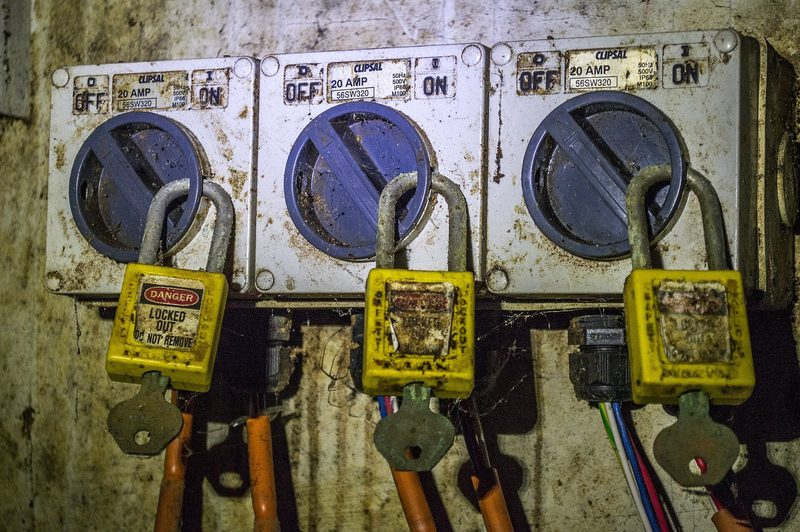

*Bloqueo y etiquetado: candados «Danger – Locked out» en tres interruptores. darkday (Flickr), CC BY 2.0, [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Power_Lockout_%2813421721974%29.jpg).*

En la sección 6 encontró un hueco: el modelo permite que Luis retire el bloqueo de Ana. La norma de **bloqueo y etiquetado** (en inglés, *lockout/tagout*) dice que cada persona pone su propio candado y que solo ella puede retirarlo. Para modelarla hay que **recordar quién bloqueó**:

1. Un predicado nuevo, `(bloqueado-por ?t - tecnico ?e - equipo)`.
2. `bloquear` lo agrega, con el técnico que bloquea.
3. `liberar` lo exige, con el técnico que libera, y lo elimina.

### ✏️ Ejercicio opcional: modelar la norma de bloqueo

* Complete el dominio y ejecute la celda. La comprobación resuelve la variante a) de la sección 6 con su dominio y verifica que libere la misma persona que bloqueó.

In [ ]:
# ✏️ Ejercicio opcional: solo quien bloqueó puede liberar (reemplace cada ...)
DOMINIO_CON_BLOQUEO = open(DOMINIO, encoding="utf-8").read()
DOMINIO_CON_BLOQUEO = DOMINIO_CON_BLOQUEO.replace(
    "(bloqueado ?e - equipo)",
    "(bloqueado ?e - equipo)\n    ...")                                   # 1. declare el predicado nuevo
DOMINIO_CON_BLOQUEO = DOMINIO_CON_BLOQUEO.replace(
    ":effect (and (bloqueado ?e) (not (encendido ?e))))",
    ":effect (and (bloqueado ?e) ... (not (encendido ?e))))")              # 2. bloquear registra quién bloqueó
DOMINIO_CON_BLOQUEO = DOMINIO_CON_BLOQUEO.replace(
    ":precondition (and (en ?t ?l) (ubicado ?e ?l) (bloqueado ?e) (reparado ?e))\n    :effect (and (en-servicio ?e) (encendido ?e) (not (bloqueado ?e))))",
    ":precondition (and (en ?t ?l) (ubicado ?e ?l) (bloqueado ?e) ... (reparado ?e))\n"
    "    :effect (and (en-servicio ?e) (encendido ?e) (not (bloqueado ?e)) ...))")  # 3. liberar lo exige y lo borra
comprobar.comprobar_regla_bloqueo(DOMINIO_CON_BLOQUEO, variantes["a) meta adicional"])

<a id='8'></a>
## 8 - Opcional: el mismo procedimiento como red jerárquica de tareas

Un jefe de mantenimiento no piensa en acciones sueltas. Piensa en **tareas** que se descomponen en tareas más pequeñas: «para restablecer un equipo: preparar el repuesto, intervenir con seguridad y cerrar». La **planificación jerárquica**, o **HTN** por sus siglas en inglés (*Hierarchical Task Networks*), formaliza esa forma de razonar (Erol, Hendler y Nau, 1994):

* Una **tarea compuesta** (por ejemplo, `restablecer bomba3`) no se ejecuta directamente: se descompone.
* Un **método** dice cómo descomponerla en subtareas, según el estado actual. Es una receta del oficio.
* Las **tareas primitivas** son las acciones del dominio, y forman el plan final.

En lugar de buscar entre todas las combinaciones de acciones, el planificador sigue las recetas, lo que reduce mucho la búsqueda y deja el conocimiento del oficio escrito y revisable. Por eso HTN se usa en aplicaciones reales; por ejemplo, para componer servicios web (Sirin et al., 2004). Las fases y subtareas del plan.md del Laboratorio 2C son una descomposición jerárquica escrita en lenguaje natural.

El módulo `htn_2a` trae un expansor mínimo: aplica las recetas y los efectos de cada acción, pero **no comprueba precondiciones**. Como una receta escrita a mano, puede producir un plan inválido. Por eso el plan que resulta se valida, igual que cualquier otro.

* Ejecute la siguiente celda para definir los métodos de MantenIA. Cada método es una función de Python que recibe el estado y los argumentos de la tarea, y devuelve la lista de subtareas.

In [ ]:
# Métodos HTN de MantenIA: cada uno devuelve las subtareas de una tarea compuesta
hechos = htn.hechos   # hechos(estado, "en") → [["ana", "base"], ["luis", "base"]]

def restablecer(estado, equipo):
    """Restablecer un equipo: preparar el repuesto, intervenir con seguridad y cerrar."""
    lugar = [l for e, l in hechos(estado, "ubicado") if e == equipo][0]
    tecnico = [t for t, e in hechos(estado, "certificado") if e == equipo][0]
    repuesto = [r for r, e in hechos(estado, "compatible") if e == equipo][0]
    return [("preparar", tecnico, repuesto), ("intervenir", tecnico, equipo, repuesto, lugar),
            ("cerrar", tecnico, equipo, lugar)]

def preparar(estado, tecnico, repuesto):
    """Preparar: ir a donde está el repuesto y retirarlo."""
    almacen = [l for r, l in hechos(estado, "almacenado") if r == repuesto][0]
    return [("ir", tecnico, almacen), ("retirar-repuesto", tecnico, repuesto, almacen)]

def ir(estado, tecnico, destino):
    """Ir: desplazarse solo si el técnico no está ya en el destino."""
    origen = [l for t, l in hechos(estado, "en") if t == tecnico][0]
    return [] if origen == destino else [("desplazarse", tecnico, origen, destino)]

def cerrar(estado, tecnico, equipo, lugar):
    """Cerrar: liberar el equipo."""
    return [("liberar", tecnico, equipo, lugar)]

Falta el método `intervenir`. La versión de abajo tiene un error de receta: repara antes de bloquear.

### ✏️ Ejercicio opcional: corregir una receta

* Ejecute la celda tal como está y lea el veredicto del validador. Después corrija el orden de las subtareas y vuelva a ejecutarla.

In [ ]:
# ✏️ Método intervenir: corrija el orden de las subtareas según el veredicto del validador
def intervenir(estado, tecnico, equipo, repuesto, lugar):
    """Intervenir con seguridad: ir al equipo, bloquearlo y repararlo."""
    return [("ir", tecnico, lugar),
            ("reparar", tecnico, equipo, repuesto, lugar),
            ("bloquear", tecnico, equipo, lugar)]

metodos = {"restablecer": restablecer, "preparar": preparar, "ir": ir, "intervenir": intervenir, "cerrar": cerrar}
pasos_htn, arbol = htn.expandir(ot512, [("restablecer", "bomba3")], metodos)
htn.mostrar_arbol(arbol)
p.mostrar_veredicto(u.validar(ot512, u.plan_desde_texto(ot512, "\n".join(pasos_htn)).plan), "Validación del plan HTN")

Con la receta corregida, el árbol muestra la descomposición completa: restablecer se descompone en preparar, intervenir y cerrar, y sus hojas son las 6 acciones del plan de Fast Downward. Las mismas recetas sirven para cualquier orden.

* Ejecute la siguiente celda para restablecer los dos equipos de la OT-518 con las mismas recetas (necesita el ejercicio 2 resuelto).

In [ ]:
# Aplicar las mismas recetas a los dos equipos de la OT-518
if "ot518" not in globals():
    p.nota("Primero complete el ejercicio 2 (sección 5) y ejecute la celda que traza su plan.", "aviso")
else:
    pasos_518, arbol_518 = htn.expandir(ot518, [("restablecer", "bomba3"), ("restablecer", "compresor2")], metodos)
    htn.mostrar_arbol(arbol_518)
    p.mostrar_veredicto(u.validar(ot518, u.plan_desde_texto(ot518, "\n".join(pasos_518)).plan), "Validación del plan HTN · OT-518")

<br>

### Análisis

* **Recetas en lugar de búsqueda.** El expansor no exploró alternativas: siguió las recetas. Para la OT-518 encontró en un instante un plan de 12 pasos, sin buscar.
* **Una receta mal escrita produce un plan inválido.** El error estaba en el conocimiento del oficio (el método), no en el expansor, y solo el validador lo hizo visible. Los planificadores HTN completos comprueban las precondiciones mientras descomponen, pero sus planes también se validan. Validar es barato y atrapa errores de modelado.

<a id='9'></a>
## 9 - Inténtelo usted mismo, entrega y criterios

<a id='9-1'></a>
### 9.1 - Inténtelo usted mismo

Esta sección es **opcional**. Algunas ideas para experimentar con el modelo:

* Agregue a la OT-518 un tercer equipo averiado, por ejemplo la caldera 1 de la Planta Sur con un quemador compatible en la bodega, y decida quién está certificado para ella.
* Haga que Ana empiece en la Planta Norte y observe cómo cambia la ruta.
* Pruebe el modelo del trabajo independiente TI-1 de esta sesión, en el que se describen como acciones PDDL tres o cuatro pasos de un proceso de su organización.

Para pruebas rápidas sin el notebook, el editor en línea [editor.planning.domains](https://editor.planning.domains/) resuelve y valida archivos PDDL en el navegador.

* Edite la celda siguiente y ejecútela. El ejemplo cambia la certificación de la OT-512 de Ana a Luis.

In [ ]:
# ✏️ Opcional: cambie el dominio o el problema y vuelva a resolver
mi_dominio = open(DOMINIO, encoding="utf-8").read()
mi_problema = u.variante(texto_512, quitar=["(certificado ana bomba3)"], agregar=["(certificado luis bomba3)"])
mio = u.leer_problema(mi_dominio, mi_problema)
mi_resultado = u.resolver(mio)
p.mostrar_planificacion(mi_resultado)
if mi_resultado.plan:
    p.mostrar_traza(u.trazar(mio, mi_resultado.plan))

<a id='9-2'></a>
### 9.2 - Entrega y criterios de evaluación

**Qué se entrega.** Este notebook ejecutado, con sus salidas visibles y los ejercicios ✏️ resueltos. Guárdelo (**Archivo › Guardar**) y súbalo por el canal del curso, uno por pareja, al inicio de la semana 2 del curso. Antes de entregar, use **Reiniciar** y **Ejecutar todo** para comprobar que corre de principio a fin.

| Criterio | Peso |
| :--- | :--- |
| La OT-518 formalizada: la comprobación del ejercicio 2 es exitosa | 35 % |
| Las variantes de la sección 6 interpretadas con base en los resultados | 30 % |
| La regla de la prueba de presión modelada y validada (ejercicio 3) | 25 % |
| Claridad del análisis escrito | 10 % |

Las secciones 7.2, 8 y 9.1 son opcionales y no restan si no se hacen.

### ✏️ Declaración de uso de asistentes de IA

El curso permite usar asistentes de IA generativa como herramienta de consulta, siempre que se declare cómo se usaron.

* En la celda siguiente, escriba si usaron algún asistente, para qué y cómo verificaron lo que les propuso. Si no lo usaron, escríbalo también.

**✏️ Declaración de uso de IA.** *Escriba aquí su declaración.*

<a id='conclusion'></a>
## Conclusión

Usted completó el laboratorio y recorrió el ciclo completo de la planificación clásica.

Empezó con una orden de trabajo y la convirtió en un modelo: hechos para describir el estado, acciones con precondiciones y efectos, y una meta. Un planificador de propósito general encontró el plan sin que nadie le dijera quién debía intervenir ni en qué orden, porque esas decisiones se siguen de las reglas. Un validador independiente lo certificó, y la traza mostró, paso a paso, cómo cada acción prepara la siguiente. Cuando el plan vino de una persona, el validador señaló exactamente qué precondición fallaba y en qué paso.

También vio los límites. Un planificador satisfactorio entrega planes válidos, pero no siempre los mejores. Y, sobre todo, **el validador verifica contra el modelo**: si al modelo le falta una regla, como la de quién puede retirar un candado, el validador certifica planes que la violan. Por eso modelar bien es tan importante como planificar bien.

Estas ideas siguen en el resto de la unidad:

* En el **Laboratorio 2B**, un modelo de lenguaje propondrá planes para estas mismas órdenes y traducirá órdenes escritas a PDDL. El validador de este laboratorio será el que juzgue sus respuestas.
* En el **Laboratorio 2C**, el plan será un plan.md en lenguaje natural, que valida una persona paso a paso.
* En el **trabajo independiente TI-1** de esta sesión, aplicará el mismo modelado a un proceso de su organización.

<a id='referencias'></a>
## Referencias

* Fikes, R. E. y Nilsson, N. J. (1971). STRIPS: A new approach to the application of theorem proving to problem solving. *Artificial Intelligence*, 2(3–4), 189–208. [PDF](https://ai.stanford.edu/~nilsson/OnlinePubs-Nils/PublishedPapers/strips.pdf)
* McDermott, D. et al. (1998). *PDDL — The Planning Domain Definition Language*, v. 1.2. Informe técnico CVC TR-98-003, Yale. [PDF](https://www.cs.cmu.edu/~mmv/planning/readings/98aips-PDDL.pdf)
* Hoffmann, J. y Nebel, B. (2001). The FF planning system. *JAIR*, 14, 253–302. [JAIR](https://www.jair.org/index.php/jair/article/view/10276)
* Helmert, M. (2006). The Fast Downward planning system. *JAIR*, 26, 191–246. [JAIR](https://www.jair.org/index.php/jair/article/view/10457)
* Richter, S. y Westphal, M. (2010). The LAMA planner: Guiding cost-based anytime planning with landmarks. *JAIR*, 39, 127–177. [JAIR](https://www.jair.org/index.php/jair/article/view/10676)
* Howey, R., Long, D. y Fox, M. (2004). VAL: Automatic plan validation, continuous effects and mixed initiative planning using PDDL. *ICTAI 2004*, 294–301. [Manuscrito](https://strathprints.strath.ac.uk/2550/6/strathprints002550.pdf)
* Micheli, A. et al. (2025). Unified Planning: Modeling, manipulating and solving AI planning problems in Python. *SoftwareX*, 29, 102012. [PDF abierto](https://ai.dmi.unibas.ch/papers/micheli-et-al-softwarex2025.pdf) · [Documentación](https://unified-planning.readthedocs.io/)
* Erol, K., Hendler, J. y Nau, D. S. (1994). HTN planning: Complexity and expressivity. *AAAI-94*, 1123–1128. [PDF](https://cdn.aaai.org/AAAI/1994/AAAI94-173.pdf)
* Sirin, E., Parsia, B., Wu, D., Hendler, J. y Nau, D. (2004). HTN planning for Web Service composition using SHOP2. *Journal of Web Semantics*, 1(4), 377–396. [DOI](https://doi.org/10.1016/j.websem.2004.06.005)
* Ghallab, M., Nau, D. y Traverso, P. (2025). *Acting, Planning, and Learning*. Cambridge University Press. [Editorial](https://www.cambridge.org/core/books/acting-planning-and-learning/CA9D7D25137AA950AC91A7D9F378EA0A)
* Russell, S. y Norvig, P. (2021). *Artificial Intelligence: A Modern Approach* (4.ª ed.), cap. 11. Pearson. [Contenido](https://aima.cs.berkeley.edu/contents.html)
* Bernard, D. E. et al. (2000). *Remote Agent Experiment: DS1 Technology Validation Report*. JPL Publication 00-10. [PDF](https://pds-smallbodies.astro.umd.edu/holdings/ds1-c-micas-3-rdr-visccd-borrelly-v1.0/document/doc_Apr04/DS1_Integrated_Reports_A.pdf)
* Nayak, P. P. et al. (1999). Validating the DS1 Remote Agent Experiment. *i-SAIRAS-99*. [PDF](https://ai.jpl.nasa.gov/public/documents/papers/rax-results-isairas99.pdf)
* Bresina, J. L., Jónsson, A. K., Morris, P. H. y Rajan, K. (2005). Activity planning for the Mars Exploration Rovers. *ICAPS 2005*. [PDF](https://cdn.aaai.org/ICAPS/2005/ICAPS05-005.pdf)
* Parjan, S. y Gaines, D. (2024). «In OBP we trust»: Verification and validation of the M2020 On Board Planner. *IEEE Aerospace Conference*. [PDF](https://ai.jpl.nasa.gov/public/documents/papers/parjan-ieee2024-m2020.pdf)
* Hoffmann, J., Weber, I. y Kraft, F. M. (2012). SAP speaks PDDL. *JAIR*, 44, 587–632. [JAIR](https://jair.org/index.php/jair/article/view/10773)